## Uploading the file

*Data read from `../data/` (no upload needed outside Colab).*

## Import Libraries

In [1]:
# shows the figures in the notebook (otherwise VS Code may show the first one as text only)
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

# Needs Python 3.12 for this library yellowbrick
from yellowbrick.cluster import KElbowVisualizer

# Not used since matplotlib 3.2 
# from mpl_toolkits.mplot3d import Axes3D

## Importing the CSV file

In [2]:
dataset = pd.read_csv('../data/Mall_Customers.csv')

## Dataset Information

In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


## Counting the number of nan values

In [4]:
dataset.isna().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

## Observing the data

In [5]:
dataset.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Select Numerical values

We chose the variables Age, Annual Income and Spending Score; the rest is ignored.

In [6]:
X = dataset.iloc[:,[2,3,4]].values
X

array([[ 19,  15,  39],
       [ 21,  15,  81],
       [ 20,  16,   6],
       [ 23,  16,  77],
       [ 31,  17,  40],
       [ 22,  17,  76],
       [ 35,  18,   6],
       [ 23,  18,  94],
       [ 64,  19,   3],
       [ 30,  19,  72],
       [ 67,  19,  14],
       [ 35,  19,  99],
       [ 58,  20,  15],
       [ 24,  20,  77],
       [ 37,  20,  13],
       [ 22,  20,  79],
       [ 35,  21,  35],
       [ 20,  21,  66],
       [ 52,  23,  29],
       [ 35,  23,  98],
       [ 35,  24,  35],
       [ 25,  24,  73],
       [ 46,  25,   5],
       [ 31,  25,  73],
       [ 54,  28,  14],
       [ 29,  28,  82],
       [ 45,  28,  32],
       [ 35,  28,  61],
       [ 40,  29,  31],
       [ 23,  29,  87],
       [ 60,  30,   4],
       [ 21,  30,  73],
       [ 53,  33,   4],
       [ 18,  33,  92],
       [ 49,  33,  14],
       [ 21,  33,  81],
       [ 42,  34,  17],
       [ 30,  34,  73],
       [ 36,  37,  26],
       [ 20,  37,  75],
       [ 65,  38,  35],
       [ 24,  38

## K-means

The silhouette score is a **measure of how similar an object is to its own cluster compared to other clusters**. 

The silhouette score ranges from -1 to 1, where **a high value indicates that the object is well matched to its own cluster** and poorly matched to neighboring clusters. 
- This means that if most objects have a high value for silhouette scores, then the clustering configuration is appropriate. 
- If many points have a low or negative value, then the clustering configuration may have too many or too few clusters.

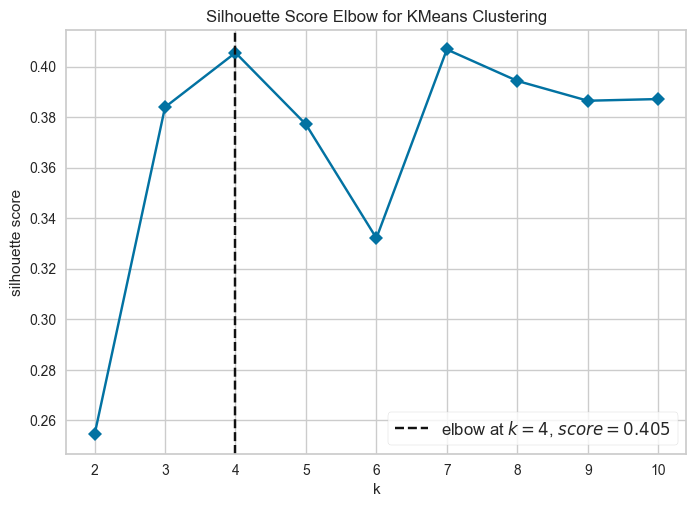

In [7]:
# Kmeans from sklearn.cluster
model = KMeans()

# silhouette score with K-Elbow method from yellowbrick.cluster 
visualizer = KElbowVisualizer(model, k = (2,11),metric='silhouette',timings=False)

visualizer.fit(X)

visualizer.show();   # ';' hides the text <Axes ...> under the figure

## K-means++

While K-means ("classical") takes k-points randomly, the K-means++ takes each following centers after the first one with a higher probability with respect to the distance on already chosen centers. 

**K-means**: 
- If the k centers are near each other, the algorithm can converge to bad clusters. 
- Results change from one execution to another. 

**K-means++**: 
- It takes the 1st center randomly. 
- Then each next center is taken with a probability as high as the point is far from the already chosen centers. 

- So the starting centers are already well spread. 
- Therefore the convergence is faster and results are better and more stable. 

In [8]:
kmeansmodel = KMeans(n_clusters=5, init='k-means++',random_state=42)
y_kmeans = kmeansmodel.fit_predict(X)

The default settings of `scikit-learn` for `KMeans()` fixes already `random_state=42` to obtain the same results at each execution. 

In [9]:
y_kmeans

array([2, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 2,
       0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 0, 0, 0, 0, 0, 0,
       0, 4, 0, 0, 0, 4, 0, 0, 0, 0, 4, 0, 4, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1])

`y_kmeans` displays the cluster of each client: from 0 to 4 here, from 1 to 5 in the column `y_means` below (`y_kmeans + 1`).

In [10]:
dataset['y_means'] = y_kmeans+1
dataset.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),y_means
0,1,Male,19,15,39,3
1,2,Male,21,15,81,3
2,3,Female,20,16,6,1
3,4,Female,23,16,77,3
4,5,Female,31,17,40,1


## Scatter Plot

**Code Explaination:**

- `y_kmeans` contains the cluster of each client, predicted by the final model `kmeansmodel`.

- scatter function is a function from Matplotlib is used to create a scatter plot.

- `X[y_kmeans == 4, 0]`: X is the dataset used for clustering, containing Age, Annual Income and Spending Score.

- `y_kmeans == 4` creates a Boolean mask that selects only the rows in X where y_kmeans
(the predicted cluster labels from the model) is 4,
meaning those points are classified into Cluster 4.

- `X[y_kmeans == 4, 0]` extracts the first column (index 0) of X for Cluster 4 data points,
which corresponds to Age.

- `X[y_kmeans == 4, 1]`:
This extracts the second column (index 1) of X for Cluster 4 data points,
which corresponds to Annual Income
`s = 100`, parameter set size of each point

In [11]:
T = np.array([[1,2,3],
              [4,5,6]])

In [12]:
T[:,2]

array([3, 6])

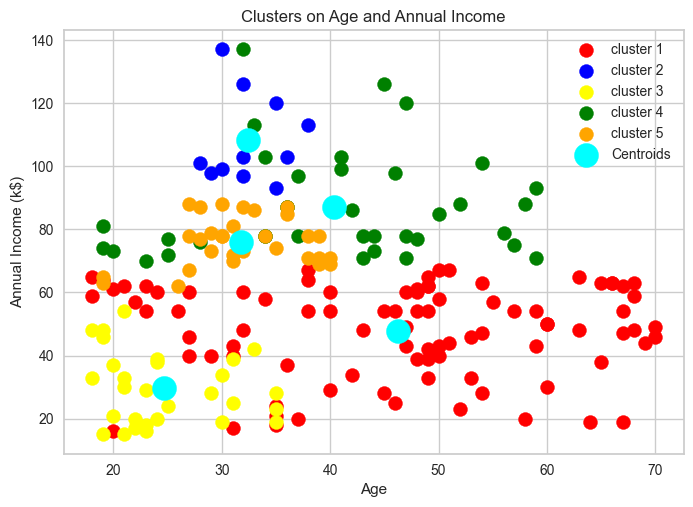

In [13]:
plt.scatter(X[y_kmeans == 0,0],X[y_kmeans==0,1],
            s=100,c='red',label='cluster 1')
plt.scatter(X[y_kmeans == 1,0],X[y_kmeans==1,1],
            s=100,c='blue',label='cluster 2')
plt.scatter(X[y_kmeans == 2,0],X[y_kmeans==2,1],
            s=100,c='yellow',label='cluster 3')
plt.scatter(X[y_kmeans == 3,0],X[y_kmeans==3,1],
            s=100,c='green',label='cluster 4')
plt.scatter(X[y_kmeans == 4,0],X[y_kmeans==4,1],
            s=100,c='orange',label='cluster 5')
plt.scatter(kmeansmodel.cluster_centers_[:,0],
            kmeansmodel.cluster_centers_[:,1],
            s=300,c='cyan',label='Centroids')

# axes: the 2 first columns of X are Age and Annual Income
plt.xlabel('Age')
plt.ylabel('Annual Income (k$)')
plt.title('Clusters on Age and Annual Income')
plt.legend()
plt.show()

## 3D plot

**Correction** (Charlotte): `plt.cm.get_cmap` no longer exists in matplotlib >= 3.

New name is: `plt.get_cmap`

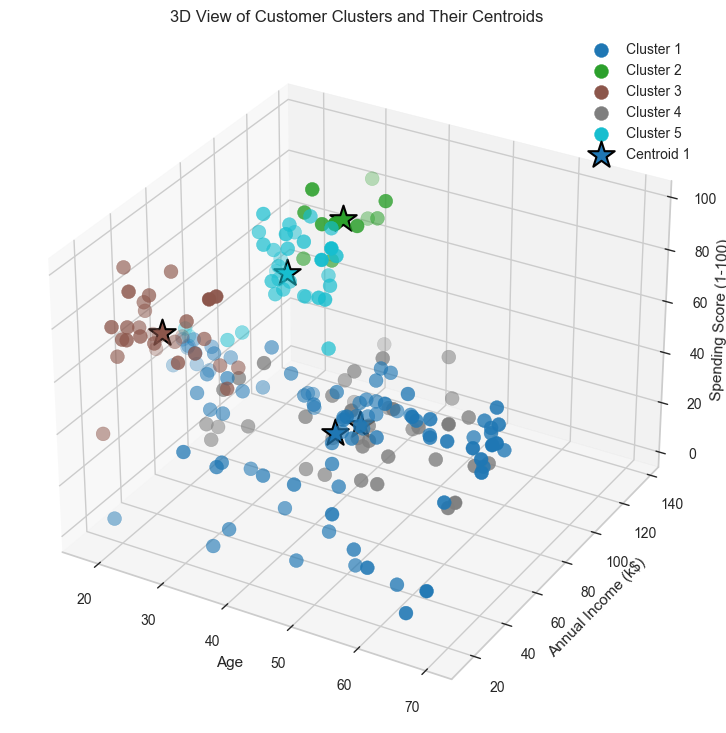

In [14]:
# Create a new figure for the 3D plot
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Get the exact number of clusters from the model
n_clusters = kmeansmodel.n_clusters

# Generate distinct colors for each cluster dynamically
colors = plt.get_cmap('tab10', n_clusters)

# Plot the data points for each of the 4 clusters
for i in range(n_clusters):
    ax.scatter(X[y_kmeans == i, 0],  # Age
               X[y_kmeans == i, 1],  # Annual Income
               X[y_kmeans == i, 2],  # Spending Score
               s=100,
               color=colors(i),
               label=f'Cluster {i+1}')

# Plot all 4 corresponding centroids
centroids = kmeansmodel.cluster_centers_
for i in range(n_clusters):
    ax.scatter(centroids[i, 0],
               centroids[i, 1],
               centroids[i, 2],
               s=400,
               color=colors(i),
               marker='*',
               edgecolors='black',
               linewidths=1.5,
               label=f'Centroid {i+1}' if i == 0 else "")  # Single label for legend clarity

# Label the 3D axes
ax.set_title('3D View of Customer Clusters and Their Centroids')
ax.set_xlabel('Age')
ax.set_ylabel('Annual Income (k$)')
ax.set_zlabel('Spending Score (1-100)')
ax.legend()
plt.show()